In [1]:
import signalTreatment as st
import splitSignal as ss
import dataSorting as ds
import numpy as np
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report
import os
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV
from prettytable import PrettyTable

In [2]:
import dataSorting as ds
from confusionMatrix import ConfusionMatrix

In [3]:
def get_file_names_from_directory(directory):
    return [f for f in os.listdir(directory) if ds.parseFileName(f)[0]!="Strasser"]

def get_file_names():
    l1 = get_file_names_from_directory("signaux EEG")
    l2 = get_file_names_from_directory("signaux EEG Prisha")
    l = [*l1, *l2]
    return l

In [4]:
def get_all_data_and_labels():
    X, y = np.array([]), np.array([]) 
    file_names = get_file_names()
    for i in range(len(file_names)):
        
        X_file, y_file = ds.getDataAndLabels(file_names[i])
        # print(len(X_file), len(y_file))
        
        if i == 0:
            X, y = X_file, y_file
        else:
            X =np.vstack((X, X_file))
            y = np.vstack((y, y_file))
    return X, y

def get_all_data_and_labels_by_person():
    data_persons = {"Revillon":[np.array([]),np.array([])], "Chandiramani":[np.array([]),np.array([])], "Kayssieh":[np.array([]),np.array([])], "Strasser":[np.array([]),np.array([])], "Yvert":[np.array([]),np.array([])]}

    X, y = np.array([]), np.array([]) 
    file_names = get_file_names()
    for i in range(len(file_names)):
        name, email, sessionId, testId = ds.parseFileName(file_names[i])
        
        X_file, y_file = ds.getDataAndLabels(file_names[i])
        if data_persons[name][0].size==0 :
            data_persons[name][0] = X_file
            data_persons[name][1] = y_file
        else:
            data_persons[name][0] = np.vstack((data_persons[name][0], X_file))
            data_persons[name][1] = np.vstack((data_persons[name][1], y_file))
    return data_persons

In [5]:
dico_persons = get_all_data_and_labels_by_person()

In [6]:
def get_data_from_persons(personnes):
    x = np.array([])
    y= np.array([])
    for i in range(len(personnes)):
        if i == 0:
            x = dico_persons[personnes[i]][0]
            y = dico_persons[personnes[i]][1]
        else:
            x = np.vstack((x, dico_persons[personnes[i]][0]))
            y = np.vstack((y, dico_persons[personnes[i]][1]))
    return x, y

In [7]:

def fit(X_train, y_train, X_test, y_test, clf):
    # Entraîner le modèle
 
# Initialiser le classifieur

    # Entraîner le modèle
    clf.fit(X_train, y_train)



    import matplotlib.pyplot as plt
    confusion_1 = ConfusionMatrix(labels=['0','1','2'])
    confusion_1.update(clf.predict(X_test), y_test)
    confusion_1.plot()

    confusion_2 = ConfusionMatrix(labels=['0','1','2'])
    confusion_2.update(clf.predict(X_train), y_train)
    confusion_2.plot()



(3222, 36, 64) (3222, 3)
[[ 31.  29.   5.]
 [141. 624. 100.]
 [  4.  22.  11.]]
the model accuracy is  0.688728024819028
+---+-----------+--------+-------------+---------+
|   | Precision | Recall | Specificity | F1score |
+---+-----------+--------+-------------+---------+
| 0 |   0.477   | 0.176  |    0.957    |    0    |
| 1 |   0.721   | 0.924  |    0.175    |    1    |
| 2 |   0.297   | 0.095  |    0.969    |    0    |
+---+-----------+--------+-------------+---------+


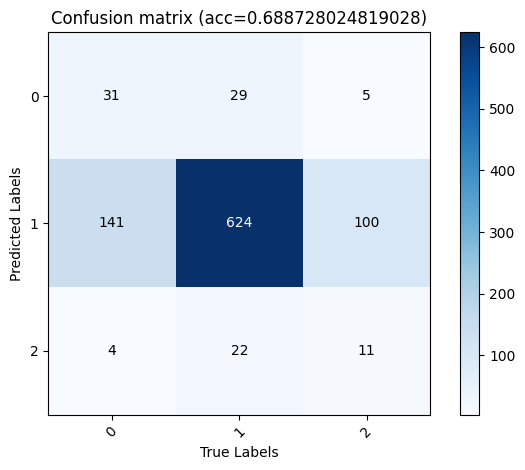

[[ 393.    0.    0.]
 [   0. 1582.    0.]
 [   0.    0.  280.]]
the model accuracy is  1.0
+---+-----------+--------+-------------+---------+
|   | Precision | Recall | Specificity | F1score |
+---+-----------+--------+-------------+---------+
| 0 |    1.0    |  1.0   |     1.0     |    1    |
| 1 |    1.0    |  1.0   |     1.0     |    1    |
| 2 |    1.0    |  1.0   |     1.0     |    1    |
+---+-----------+--------+-------------+---------+


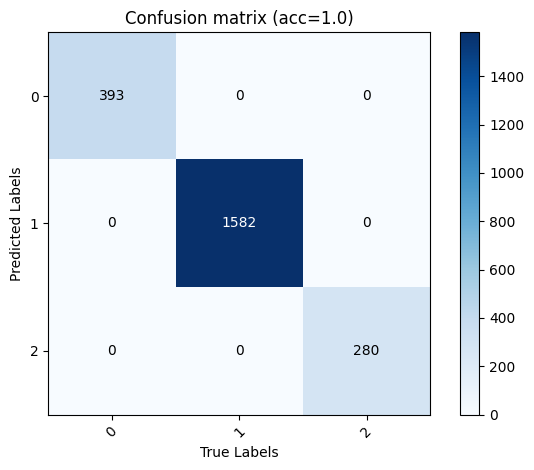

In [8]:
# X, y = get_all_data_and_labels()
X, y = get_data_from_persons(["Yvert", "Chandiramani", "Kayssieh", "Revillon"])

print(X.shape, y.shape)
X_flat = X.reshape(X.shape[0], -1)

y_labels = np.argmax(y, axis=1)

from sklearn.model_selection import train_test_split

# Diviser les données
X_train, X_test, y_train, y_test = train_test_split(X_flat, y_labels, test_size=0.3)
fit(X_train, y_train, X_test, y_test, RandomForestClassifier(n_estimators=100, random_state=42))

(706, 36, 64) (706, 3)
[[  2.  12.   2.]
 [ 35. 120.  25.]
 [  2.   9.   5.]]
the model accuracy is  0.5990566037735849
+---+-----------+--------+-------------+---------+
|   | Precision | Recall | Specificity | F1score |
+---+-----------+--------+-------------+---------+
| 0 |   0.125   | 0.051  |    0.919    |    0    |
| 1 |   0.667   | 0.851  |    0.155    |    1    |
| 2 |   0.312   | 0.156  |    0.939    |    0    |
+---+-----------+--------+-------------+---------+


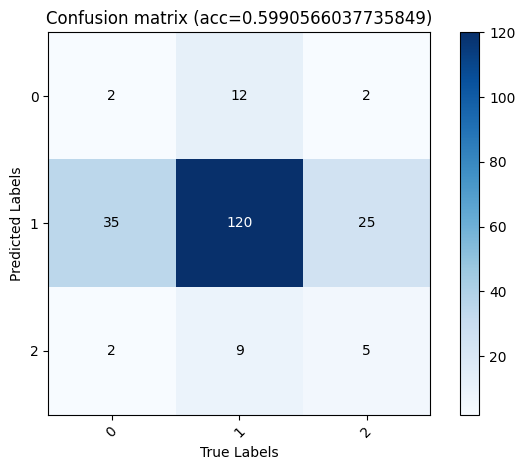

[[ 74.   0.   0.]
 [  0. 346.   0.]
 [  0.   0.  74.]]
the model accuracy is  1.0
+---+-----------+--------+-------------+---------+
|   | Precision | Recall | Specificity | F1score |
+---+-----------+--------+-------------+---------+
| 0 |    1.0    |  1.0   |     1.0     |    1    |
| 1 |    1.0    |  1.0   |     1.0     |    1    |
| 2 |    1.0    |  1.0   |     1.0     |    1    |
+---+-----------+--------+-------------+---------+


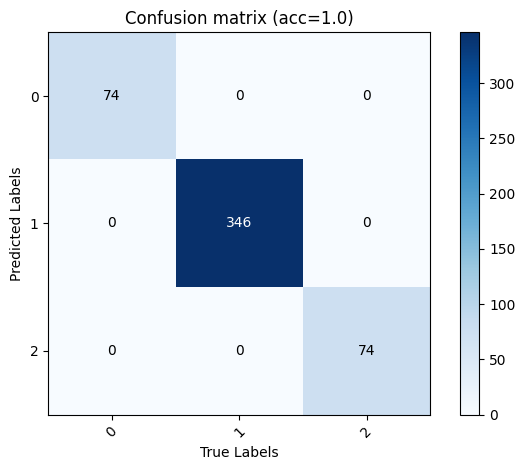

In [9]:
X, y = get_data_from_persons(["Kayssieh"])
print(X.shape, y.shape)
X_flat = X.reshape(X.shape[0], -1)

y_labels = np.argmax(y, axis=1)
from sklearn.model_selection import train_test_split

# Diviser les données
X_train, X_test, y_train, y_test = train_test_split(X_flat, y_labels, test_size=0.3)
fit(X_train, y_train, X_test, y_test, RandomForestClassifier(n_estimators=100, random_state=42))

[[110. 540.  75.]
 [  0.   0.   0.]
 [  0.   0.   0.]]
the model accuracy is  0.15172413793103448
+---+-----------+--------+-------------+---------+
|   | Precision | Recall | Specificity | F1score |
+---+-----------+--------+-------------+---------+
| 0 |   0.152   |  1.0   |     0.0     |    0    |
| 1 |    0.0    |  0.0   |     1.0     |    0    |
| 2 |    0.0    |  0.0   |     1.0     |    0    |
+---+-----------+--------+-------------+---------+


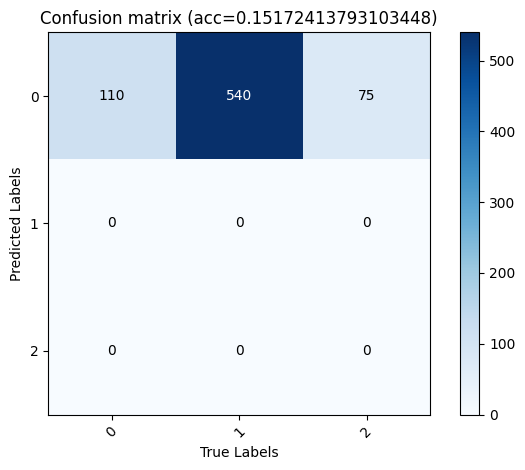

[[ 459.    0.    0.]
 [   0. 1717.    0.]
 [   0.    0.  321.]]
the model accuracy is  1.0
+---+-----------+--------+-------------+---------+
|   | Precision | Recall | Specificity | F1score |
+---+-----------+--------+-------------+---------+
| 0 |    1.0    |  1.0   |     1.0     |    1    |
| 1 |    1.0    |  1.0   |     1.0     |    1    |
| 2 |    1.0    |  1.0   |     1.0     |    1    |
+---+-----------+--------+-------------+---------+


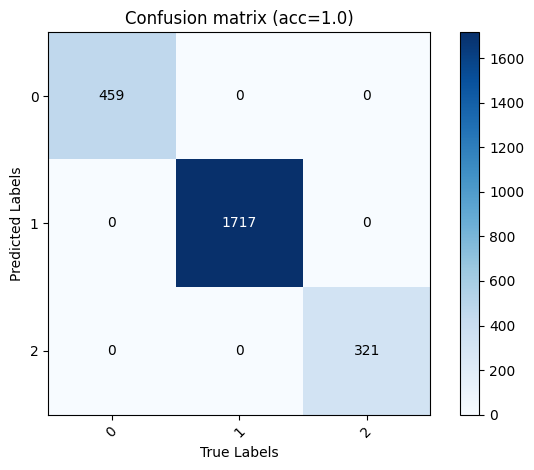

In [10]:
X_train, y_train = get_data_from_persons(["Yvert", "Chandiramani", "Kayssieh"])
X_test, y_test = get_data_from_persons(["Revillon"])

X_train = X_train.reshape(X_train.shape[0], -1)
X_test = X_test.reshape(X_test.shape[0], -1)

y_train = np.argmax(y_train, axis=1)
y_test = np.argmax(y_test, axis=1)

fit(X_train, y_train, X_test, y_test, RandomForestClassifier(n_estimators=100, random_state=42))